# 07 - Data set para la red

## OBJETIVO

Preparar los datos para el entrenamiento de la red, para esto separaremos una parte de los datos para el **train**, y otra para la validacion de la misma.

## 1. Importacion

In [1]:
import sys
sys.path.append("..")

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader

from src.utils import fijar_semillas, SEED
from src.dataset import LesionDataset, get_transforms, MEDIA, DESVIO

fijar_semillas()

PROCESSED = Path("../data/processed")
train_df = pd.read_csv(PROCESSED / "train.csv")
print(train_df.shape, train_df["dx"].value_counts().to_dict())

(982, 9) {'mel': 491, 'nv': 491}


## 2. Separacion de validacion 
Para este apartado apartamos una parte del train como validacion.

In [2]:
cnn_train_df, val_df = train_test_split(
    train_df,
    test_size=0.2,
    stratify=train_df["etiqueta"],
    random_state=SEED,
)

cnn_train_df.to_csv(PROCESSED / "train_cnn.csv", index=False)
val_df.to_csv(PROCESSED / "val_cnn.csv", index=False)

print("Entrenamiento:", len(cnn_train_df), cnn_train_df["dx"].value_counts().to_dict())
print("Validación:", len(val_df), val_df["dx"].value_counts().to_dict())
assert set(cnn_train_df["image_id"]).isdisjoint(set(val_df["image_id"]))

Entrenamiento: 785 {'mel': 393, 'nv': 392}
Validación: 197 {'nv': 99, 'mel': 98}


## 3. Datasets y DataLoaders


In [3]:
ds_train = LesionDataset(cnn_train_df, get_transforms(entrenamiento=True))
ds_val = LesionDataset(val_df, get_transforms(entrenamiento=False))

generador = torch.Generator().manual_seed(SEED)
dl_train = DataLoader(ds_train, batch_size=32, shuffle=True, num_workers=0, generator=generador)
dl_val = DataLoader(ds_val, batch_size=32, shuffle=False, num_workers=0)

imgs, etiquetas = next(iter(dl_train))
print(imgs.shape, etiquetas.shape)   # torch.Size([32, 3, 224, 224]) torch.Size([32])

torch.Size([32, 3, 224, 224]) torch.Size([32])


## 4. Revision d

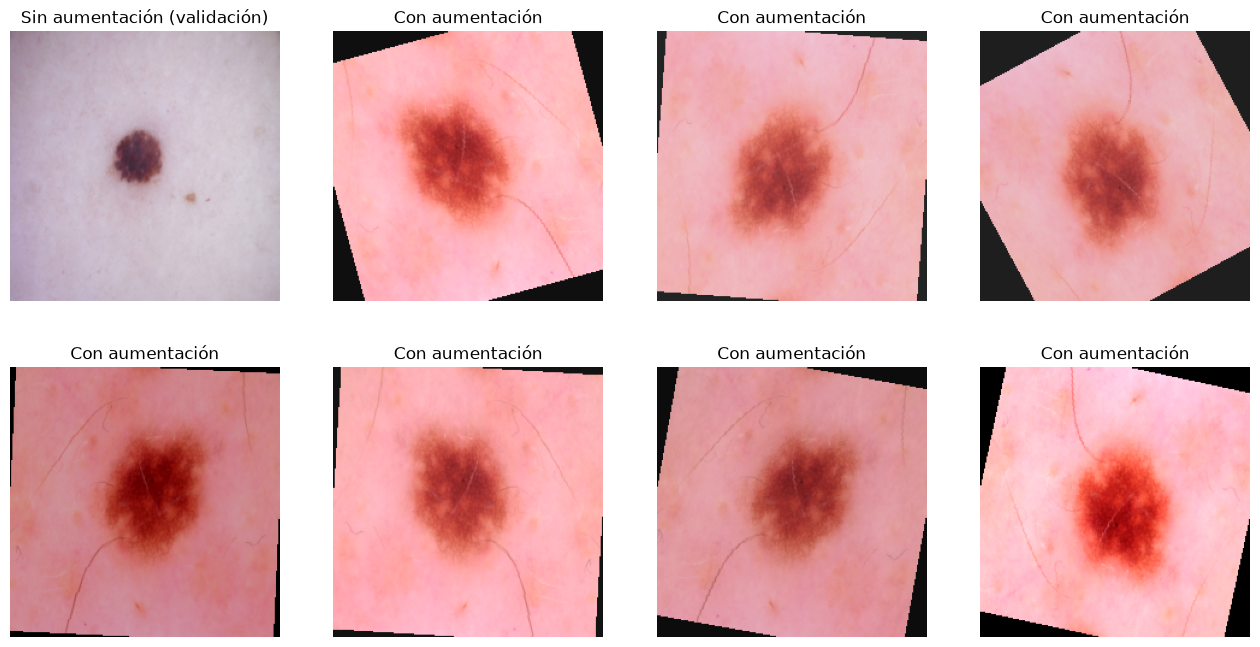

In [4]:
def desnormalizar(t):
    media = torch.tensor(MEDIA).view(3, 1, 1)
    desvio = torch.tensor(DESVIO).view(3, 1, 1)
    return (t * desvio + media).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axs = plt.subplots(2, 4, figsize=(16, 8))
axs[0, 0].imshow(desnormalizar(ds_val[0][0]))
axs[0, 0].set_title("Sin aumentación (validación)")
for ax in list(axs.ravel())[1:]:
    ax.imshow(desnormalizar(ds_train[0][0]))
    ax.set_title("Con aumentación")
for ax in axs.ravel():
    ax.axis("off")
plt.show()